In [1]:
# 1. Importing libraries
import pandas as pd
import numpy as np

# 2. Load the RFM data we created in the previous step
rfm = pd.read_csv("../data/processed/rfm_segments.csv")

#3. Create the 'Churn' target column
#If Recency > 90 days, we consider them 'Churned' (1), otherwise 'Active' (0)
rfm['Churn'] = (rfm['Recency'] > 90).astype(int)

# 4. Let`s see the balance of our target variable
print("Total Customers:", len(rfm))
print("Churned (1):", rfm['Churn'].sum())
print("Active (0):", len(rfm) - rfm['Churn'].sum())
print(f"Churn Rate: {rfm['Churn'].mean() * 100: .2f}%")

# Let`s look at the first few rows
rfm.head()

Total Customers: 5852
Churned (1): 2967
Active (0): 2885
Churn Rate:  50.70%


,CustomerID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score,Segment,Churn
0,12346,326,3,77352.96,2,2,4,224,At Risk,1
1,12347,2,8,4921.53,4,4,4,444,VIP,0
2,12348,75,5,1658.40,3,3,3,333,VIP,0
3,12349,19,3,3678.69,4,2,4,424,Loyal,0
4,12350,310,1,294.40,2,1,1,211,Lost,1


In [4]:
# --- Feature Engineering --- 
# 1. Average Order Value (AOV) 
rfm['AvgOrderValue'] = rfm['Monetary'] / rfm['Frequency']

# 2. Replace infinite values (if Frequency was 0, though our data shouldn`t have 0)
rfm['AvgOrderValue'] = rfm['AvgOrderValue'].replace([np.inf, -np.inf], 0)

# 3. Let`s look at the new column and the distribution of our target
print(rfm[['CustomerID', 'Recency', 'Frequency', 'Monetary','AvgOrderValue', 'Churn']].head())

# 4. Check for missing values in our new feature
print("\nMissing values:", rfm['AvgOrderValue'].isna().sum())

   CustomerID  Recency  Frequency  Monetary  AvgOrderValue  Churn
0       12346      326          3  77352.96    25784.32000      1
1       12347        2          8   4921.53      615.19125      0
2       12348       75          5   1658.40      331.68000      0
3       12349       19          3   3678.69     1226.23000      0
4       12350      310          1    294.40      294.40000      1

Missing values: 0


In [5]:
# 1. Define Features (X) WITHOUT Recency
# We remove Recency because we used it to define Churn (Target), which causes Data Leakage.
from sklearn.model_selection import train_test_split
features = ['Frequency', 'Monetary', 'AvgOrderValue']
X = rfm[features]
y = rfm['Churn']

# 2. Split again
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print(f"Total data: {len(X)}")
print(f"Training set: {len(X_train)} (80%)")
print(f"Test set: {len(X_test)} (20%)")
print(f"\nChurn rate in Train: {y_train.mean()*100:.2f}%")
print(f"Churn rate in Test: {y_test.mean()*100:.2f}%")

Total data: 5852
Training set: 4681 (80%)
Test set: 1171 (20%)

Churn rate in Train: 50.69%
Churn rate in Test: 50.73%


In [6]:
# 1. Import the Random Forest Classifier
from sklearn.ensemble import RandomForestClassifier

# 2. Initialize the model
# n_estimators=100 means we are building 100 decision trees
# random_state=42 is for reproducibility
model = RandomForestClassifier(n_estimators=100, random_state= 42)

# 3. Train the model (Fit it on the training data)
model.fit(X_train, y_train)
print("✅ Model trained successfully!")

✅ Model trained successfully!


In [7]:
# 1. Import evaluation metrics
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# 2. Make predictions on the test set
y_pred = model.predict(X_test)

# 3. Calculate Accuracy
accuracy = accuracy_score(y_test, y_pred)
print(f"Model Accuracy: {accuracy * 100:.2f}%\n")

# 4. Print a detailed Classification Report
print("Classification Report:")
print(classification_report(y_test, y_pred))

# 5. Show the Confusion Matrix
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Model Accuracy: 61.91%

Classification Report:
              precision    recall  f1-score   support

           0       0.61      0.63      0.62       577
           1       0.63      0.61      0.62       594

    accuracy                           0.62      1171
   macro avg       0.62      0.62      0.62      1171
weighted avg       0.62      0.62      0.62      1171

Confusion Matrix:
[[362 215]
 [231 363]]


         Feature  Importance
1       Monetary    0.467939
2  AvgOrderValue    0.392056
0      Frequency    0.140005


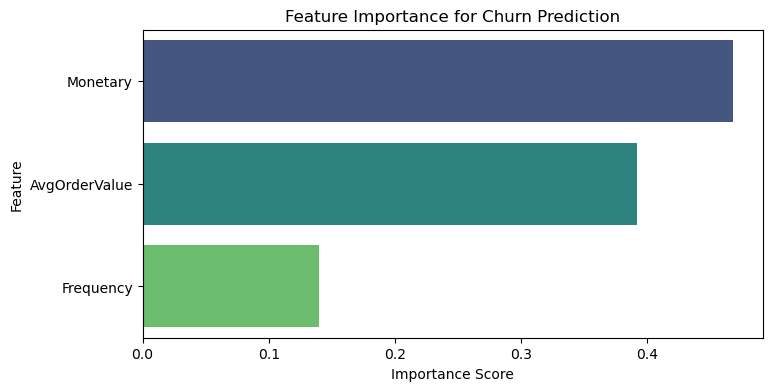

In [8]:
# 1. Get feature importances from our trained model
importances = model.feature_importances_

# 2. Create a DataFrame to display them nicely
feature_importance_df = pd.DataFrame({
    'Feature': X.columns,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

# 3. Print the results
print(feature_importance_df)

# 4. Visualize it with a bar chart
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 4))
sns.barplot(x='Importance', y='Feature', data=feature_importance_df, hue='Feature',palette='viridis',legend = False)
plt.title('Feature Importance for Churn Prediction')
plt.xlabel('Importance Score')
plt.ylabel('Feature')
plt.show()